# Exercise Habits vs Sleep Quality

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency


In [33]:
excersie_level = np.array(["low","moderate","high"])
good_sleep_observed_freq = np.array([20,45,40])
average_sleep_observed_freq = np.array([40,50,20])
poor_sleep_observed_freq = np.array([50,25,10])
observed_df = pd.DataFrame({"Excersie_level":excersie_level,"good_sleep":good_sleep_observed_freq,"Average_sleep":average_sleep_observed_freq,"poor_Sleep":poor_sleep_observed_freq})
observed_df

,Excersie_level,good_sleep,Average_sleep,poor_Sleep
0,low,20,40,50
1,moderate,45,50,25
2,high,40,20,10


In [45]:
observed_freq = observed_df[["good_sleep","Average_sleep","poor_Sleep"]]
row_wise_sum = observed_df.sum(axis=1,numeric_only=True)
print("row wise sum : \n",row_wise_sum)
column_wise_sum = observed_df.sum(axis=0,numeric_only=True)
print("columns wise sum : ",column_wise_sum)
total_sum = observed_freq.sum().sum()
print("total sum : ",total_sum)


row wise sum : 
 0    110
1    120
2     70
dtype: int64
columns wise sum :  good_sleep       105
Average_sleep    110
poor_Sleep        85
dtype: int64
total sum :  300


In [46]:
expected_freq = np.outer(row_wise_sum ,column_wise_sum/total_sum)
expected_df = pd.DataFrame(expected_freq,index=excersie_level,columns= observed_freq.columns)
expected_df

,good_sleep,Average_sleep,poor_Sleep
low,38.5,40.333333,31.166667
moderate,42.0,44.000000,34.000000
high,24.5,25.666667,19.833333


In [ ]:

chi_square_stats,p_value,dof,expected_freq = chi2_contingency(observed_freq)
print("chi square stats " ,chi_square_stats)
print("p value : ",p_value)
print("dof : ",dof)
print("expected_freq : ",expected_freq)

chi square stats  39.62031093429107
p value :  5.18601919268648e-08
dof :  4
expected_freq :  [[38.5        40.33333333 31.16666667]
 [42.         44.         34.        ]
 [24.5        25.66666667 19.83333333]]


In [49]:
alpha = 0.05
if p_value < alpha :
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: There is a enough evidence that the excersie level and sleep quality are related .")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Conclusion: There is not enough evidence of a significant relationship between exercise level and sleep quality.")



Decision: Reject the null hypothesis.
Conclusion: There is a enough evidence that the excersie level and sleep quality are related .


<Figure size 900x800 with 0 Axes>

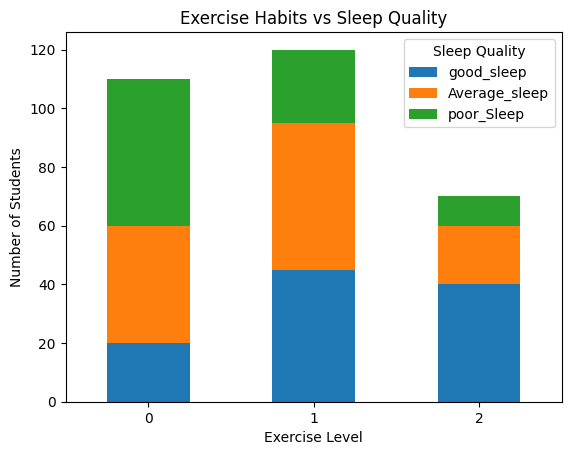

In [43]:
x = np.arange(len(observed_freq.columns))
plt.figure(figsize=(9,8))
width = 0.35
observed_df.plot(kind = "bar",stacked= True)
plt.title("Exercise Habits vs Sleep Quality")
plt.xlabel("Exercise Level")
plt.ylabel("Number of Students")
plt.legend(title="Sleep Quality")
plt.xticks(rotation=0)
plt.show()